#Correct path setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Current working directory:", Path.cwd())

Current working directory: c:\Users\User\Desktop\Customer_Churn_Prediction\notebooks


#Correct path setup

In [3]:
cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    cwd.parent.parent
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    expected_file = (
        candidate
        / "data"
        / "processed"
        / "customer_churn_cleaned.csv"
    )

    if expected_file.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find customer_churn_cleaned.csv. "
        "Please run 01_data_quality.ipynb first."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "customer_churn_cleaned.csv"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
)

METRIC_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "metrics"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRIC_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset exists:", DATA_PATH.exists())

Project root: C:\Users\User\Desktop\Customer_Churn_Prediction
Dataset path: C:\Users\User\Desktop\Customer_Churn_Prediction\data\processed\customer_churn_cleaned.csv
Dataset exists: True


#Load cleaned data

In [4]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully.
Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#Quick quality check

In [5]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate customer IDs:")
print(df["customerID"].duplicated().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows:
0

Duplicate customer IDs:
0


#Create ChurnFlag

In [6]:
df["ChurnFlag"] = (
    df["Churn"] == "Yes"
).astype(int)

df[
    [
        "customerID",
        "Churn",
        "ChurnFlag"
    ]
].head()

,customerID,Churn,ChurnFlag
0,7590-VHVEG,No,0
1,5575-GNVDE,No,0
2,3668-QPYBK,Yes,1
3,7795-CFOCW,No,0
4,9237-HQITU,Yes,1


#Overall churn summary

In [7]:
churn_summary = pd.DataFrame({
    "Count":
        df["Churn"].value_counts(),

    "Percentage":
        df["Churn"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
})

churn_summary

,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


In [8]:
overall_churn_rate = (
    df["ChurnFlag"].mean()
    * 100
)

print(
    f"Overall churn rate: "
    f"{overall_churn_rate:.2f}%"
)

Overall churn rate: 26.54%


#Visualization 1: Churn distribution

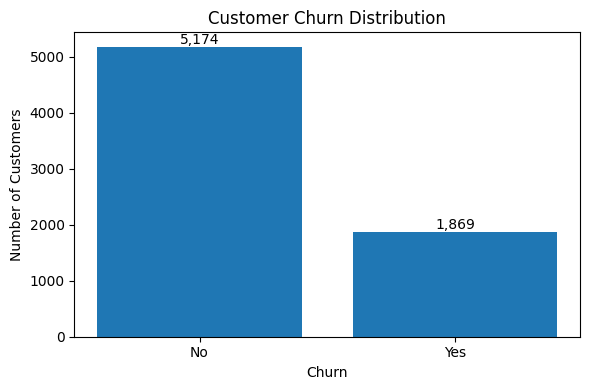

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\figures\01_churn_distribution.png


In [9]:
churn_counts = (
    df["Churn"]
    .value_counts()
    .reindex(["No", "Yes"])
)

plt.figure(
    figsize=(6, 4)
)

plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title(
    "Customer Churn Distribution"
)

plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for i, value in enumerate(
    churn_counts.values
):
    plt.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "01_churn_distribution.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    plot_path
)

#Contract analysis

In [10]:
contract_summary = (
    df.groupby("Contract")
    .agg(
        Customers=(
            "customerID",
            "count"
        ),

        Churned=(
            "ChurnFlag",
            "sum"
        ),

        Churn_Rate=(
            "ChurnFlag",
            "mean"
        )
    )
)

contract_summary[
    "Churn_Rate"
] = (
    contract_summary[
        "Churn_Rate"
    ]
    * 100
).round(2)

contract_summary = (
    contract_summary
    .sort_values(
        "Churn_Rate",
        ascending=False
    )
)

contract_summary

,Customers,Churned,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


Visualization 2: Churn by contract

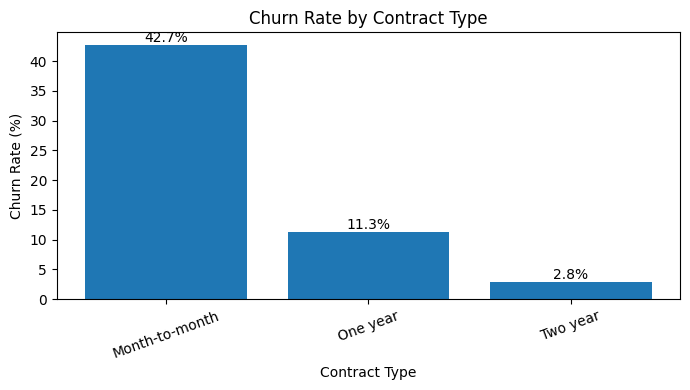

In [11]:
plt.figure(
    figsize=(7, 4)
)

plt.bar(
    contract_summary.index,
    contract_summary[
        "Churn_Rate"
    ]
)

plt.title(
    "Churn Rate by Contract Type"
)

plt.xlabel(
    "Contract Type"
)

plt.ylabel(
    "Churn Rate (%)"
)

plt.xticks(
    rotation=20
)

for i, value in enumerate(
    contract_summary[
        "Churn_Rate"
    ].values
):

    plt.text(
        i,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "02_churn_by_contract.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Visualization 3: Tenure vs churn

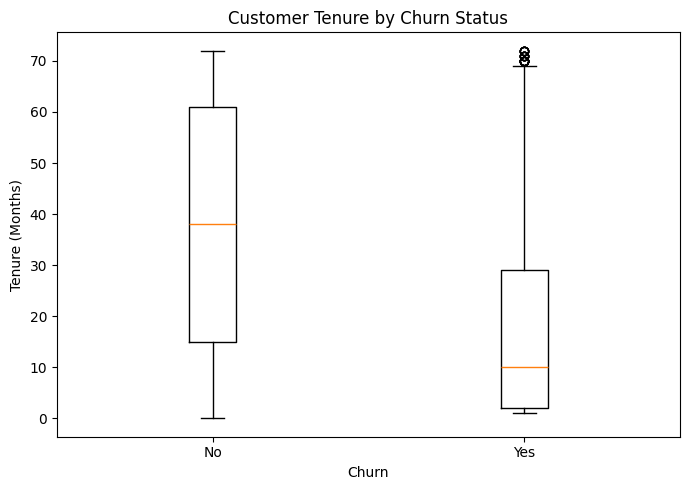

In [13]:
tenure_no = df.loc[
    df["Churn"] == "No",
    "tenure"
]

tenure_yes = df.loc[
    df["Churn"] == "Yes",
    "tenure"
]

plt.figure(
    figsize=(7, 5)
)

plt.boxplot(
    [
        tenure_no,
        tenure_yes
    ],
    tick_labels=[
        "No",
        "Yes"
    ]
)

plt.title(
    "Customer Tenure by Churn Status"
)

plt.xlabel("Churn")
plt.ylabel(
    "Tenure (Months)"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "03_tenure_by_churn.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Tenure statistics

In [14]:
tenure_summary = (
    df.groupby("Churn")[
        "tenure"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max"
        ]
    )
    .round(2)
)

tenure_summary

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


#Visualization 4: Monthly charges vs churn

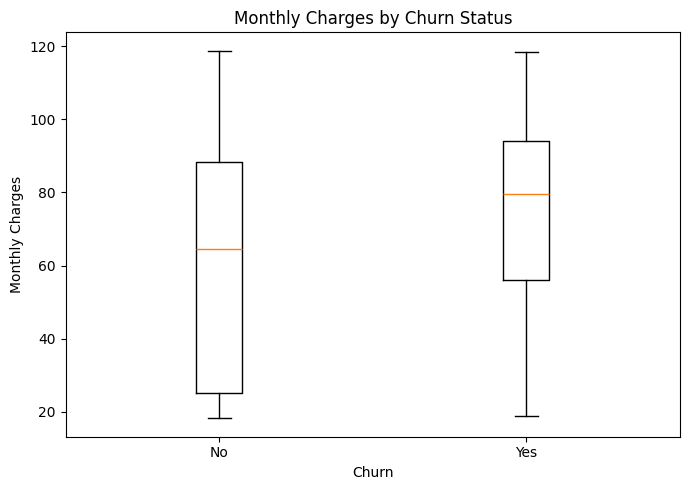

In [15]:
monthly_no = df.loc[
    df["Churn"] == "No",
    "MonthlyCharges"
]

monthly_yes = df.loc[
    df["Churn"] == "Yes",
    "MonthlyCharges"
]

plt.figure(
    figsize=(7, 5)
)

plt.boxplot(
    [
        monthly_no,
        monthly_yes
    ],
    tick_labels=[
        "No",
        "Yes"
    ]
)

plt.title(
    "Monthly Charges by Churn Status"
)

plt.xlabel("Churn")

plt.ylabel(
    "Monthly Charges"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "04_monthly_charges_by_churn.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Charge statistics

In [16]:
charges_summary = (
    df.groupby("Churn")[
        [
            "MonthlyCharges",
            "TotalCharges"
        ]
    ]
    .agg(
        [
            "mean",
            "median"
        ]
    )
    .round(2)
)

charges_summary

MonthlyCharges        TotalCharges         
                mean median         mean   median
Churn                                            
No             61.27  64.43      2549.91  1679.52
Yes            74.44  79.65      1531.80   703.55

#Internet service analysis

In [17]:
internet_summary = (
    df.groupby(
        "InternetService"
    )
    .agg(
        Customers=(
            "customerID",
            "count"
        ),

        Churned=(
            "ChurnFlag",
            "sum"
        ),

        Churn_Rate=(
            "ChurnFlag",
            "mean"
        )
    )
)

internet_summary[
    "Churn_Rate"
] = (
    internet_summary[
        "Churn_Rate"
    ]
    * 100
).round(2)

internet_summary = (
    internet_summary
    .sort_values(
        "Churn_Rate",
        ascending=False
    )
)

internet_summary

,Customers,Churned,Churn_Rate
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40


#Visualization 5: Internet service

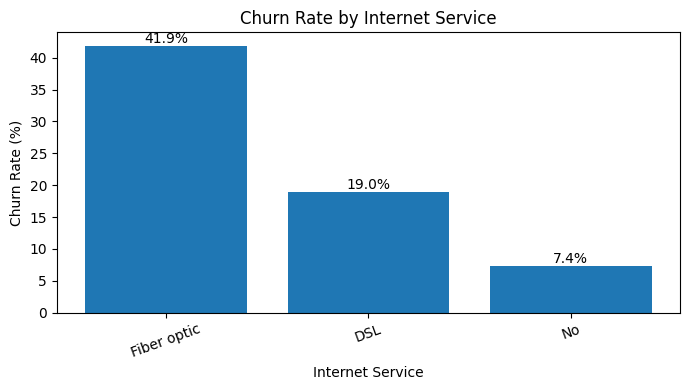

In [18]:
plt.figure(
    figsize=(7, 4)
)

plt.bar(
    internet_summary.index,
    internet_summary[
        "Churn_Rate"
    ]
)

plt.title(
    "Churn Rate by Internet Service"
)

plt.xlabel(
    "Internet Service"
)

plt.ylabel(
    "Churn Rate (%)"
)

plt.xticks(
    rotation=20
)

for i, value in enumerate(
    internet_summary[
        "Churn_Rate"
    ].values
):

    plt.text(
        i,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "05_churn_by_internet_service.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Payment method analysis

In [19]:
payment_summary = (
    df.groupby(
        "PaymentMethod"
    )
    .agg(
        Customers=(
            "customerID",
            "count"
        ),

        Churned=(
            "ChurnFlag",
            "sum"
        ),

        Churn_Rate=(
            "ChurnFlag",
            "mean"
        )
    )
)

payment_summary[
    "Churn_Rate"
] = (
    payment_summary[
        "Churn_Rate"
    ]
    * 100
).round(2)

payment_summary = (
    payment_summary
    .sort_values(
        "Churn_Rate",
        ascending=True
    )
)

payment_summary

,Customers,Churned,Churn_Rate
PaymentMethod,,,
Credit card (automatic),1522,232,15.24
Bank transfer (automatic),1544,258,16.71
Mailed check,1612,308,19.11
Electronic check,2365,1071,45.29


#Visualization 6: Payment method

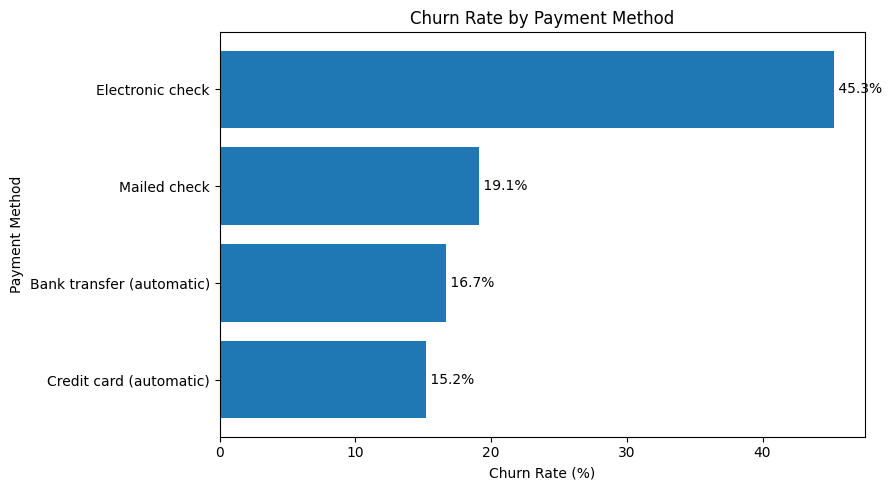

In [20]:
plt.figure(
    figsize=(9, 5)
)

plt.barh(
    payment_summary.index,
    payment_summary[
        "Churn_Rate"
    ]
)

plt.title(
    "Churn Rate by Payment Method"
)

plt.xlabel(
    "Churn Rate (%)"
)

plt.ylabel(
    "Payment Method"
)

for i, value in enumerate(
    payment_summary[
        "Churn_Rate"
    ].values
):

    plt.text(
        value,
        i,
        f" {value:.1f}%",
        va="center"
    )

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "06_churn_by_payment_method.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Tech Support Analysis

In [21]:
tech_support_summary = (
    df.groupby(
        "TechSupport"
    )
    .agg(
        Customers=(
            "customerID",
            "count"
        ),

        Churned=(
            "ChurnFlag",
            "sum"
        ),

        Churn_Rate=(
            "ChurnFlag",
            "mean"
        )
    )
)

tech_support_summary[
    "Churn_Rate"
] = (
    tech_support_summary[
        "Churn_Rate"
    ]
    * 100
).round(2)

tech_support_summary = (
    tech_support_summary
    .sort_values(
        "Churn_Rate",
        ascending=False
    )
)

tech_support_summary

,Customers,Churned,Churn_Rate
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40


#Visualization 7:Tech Support

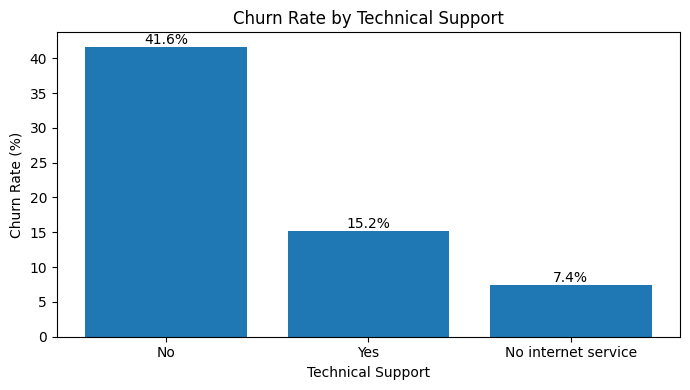

In [22]:
plt.figure(
    figsize=(7, 4)
)

plt.bar(
    tech_support_summary.index,
    tech_support_summary[
        "Churn_Rate"
    ]
)

plt.title(
    "Churn Rate by Technical Support"
)

plt.xlabel(
    "Technical Support"
)

plt.ylabel(
    "Churn Rate (%)"
)

for i, value in enumerate(
    tech_support_summary[
        "Churn_Rate"
    ].values
):

    plt.text(
        i,
        value,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "07_churn_by_tech_support.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Correlation Matrix

In [23]:
numeric_for_correlation = df[
    [
        "SeniorCitizen",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "ChurnFlag"
    ]
].copy()

correlation_matrix = (
    numeric_for_correlation
    .corr()
    .round(3)
)

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,ChurnFlag
SeniorCitizen,1.000,0.017,0.220,0.103,0.151
tenure,0.017,1.000,0.248,0.826,-0.352
MonthlyCharges,0.220,0.248,1.000,0.651,0.193
TotalCharges,0.103,0.826,0.651,1.000,-0.198
ChurnFlag,0.151,-0.352,0.193,-0.198,1.000


#Visualization & Correlation Matrix

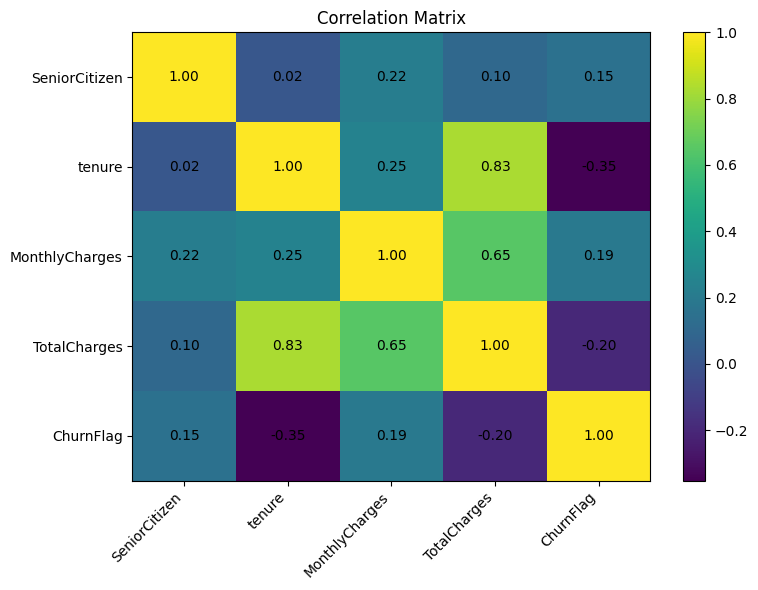

In [24]:
plt.figure(
    figsize=(8, 6)
)

image = plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(image)

plt.xticks(
    range(
        len(
            correlation_matrix.columns
        )
    ),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(
        len(
            correlation_matrix.index
        )
    ),
    correlation_matrix.index
)

for i in range(
    len(
        correlation_matrix.index
    )
):

    for j in range(
        len(
            correlation_matrix.columns
        )
    ):

        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title(
    "Correlation Matrix"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "08_correlation_matrix.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Senior Citizen Analysis

In [25]:
senior_summary = (
    df.groupby(
        "SeniorCitizen"
    )
    .agg(
        Customers=(
            "customerID",
            "count"
        ),

        Churned=(
            "ChurnFlag",
            "sum"
        ),

        Churn_Rate=(
            "ChurnFlag",
            "mean"
        )
    )
)

senior_summary[
    "Churn_Rate"
] = (
    senior_summary[
        "Churn_Rate"
    ]
    * 100
).round(2)

senior_summary

,Customers,Churned,Churn_Rate
SeniorCitizen,,,
0,5901,1393,23.61
1,1142,476,41.68


#Online Security Analysis

In [26]:
security_summary = (
    df.groupby(
        "OnlineSecurity"
    )
    .agg(
        Customers=(
            "customerID",
            "count"
        ),

        Churned=(
            "ChurnFlag",
            "sum"
        ),

        Churn_Rate=(
            "ChurnFlag",
            "mean"
        )
    )
)

security_summary[
    "Churn_Rate"
] = (
    security_summary[
        "Churn_Rate"
    ]
    * 100
).round(2)

security_summary.sort_values(
    "Churn_Rate",
    ascending=False
)

,Customers,Churned,Churn_Rate
OnlineSecurity,,,
No,3498,1461,41.77
Yes,2019,295,14.61
No internet service,1526,113,7.40


#Save all EDA tables

In [27]:
churn_summary.to_csv(
    METRIC_DIR
    / "eda_churn_summary.csv"
)

contract_summary.to_csv(
    METRIC_DIR
    / "eda_churn_by_contract.csv"
)

internet_summary.to_csv(
    METRIC_DIR
    / "eda_churn_by_internet_service.csv"
)

payment_summary.to_csv(
    METRIC_DIR
    / "eda_churn_by_payment_method.csv"
)

tech_support_summary.to_csv(
    METRIC_DIR
    / "eda_churn_by_tech_support.csv"
)

tenure_summary.to_csv(
    METRIC_DIR
    / "eda_tenure_summary.csv"
)

correlation_matrix.to_csv(
    METRIC_DIR
    / "eda_correlation_matrix.csv"
)

print(
    "EDA results saved successfully."
)

print(
    "Figures folder:",
    FIGURE_DIR.resolve()
)

print(
    "Metrics folder:",
    METRIC_DIR.resolve()
)

EDA results saved successfully.
Figures folder: C:\Users\User\Desktop\Customer_Churn_Prediction\outputs\figures
Metrics folder: C:\Users\User\Desktop\Customer_Churn_Prediction\outputs\metrics


#Automatically Show the most crucial findings


In [28]:
highest_contract = (
    contract_summary[
        "Churn_Rate"
    ].idxmax()
)

highest_contract_rate = (
    contract_summary.loc[
        highest_contract,
        "Churn_Rate"
    ]
)


highest_internet = (
    internet_summary[
        "Churn_Rate"
    ].idxmax()
)

highest_internet_rate = (
    internet_summary.loc[
        highest_internet,
        "Churn_Rate"
    ]
)


highest_payment = (
    payment_summary[
        "Churn_Rate"
    ].idxmax()
)

highest_payment_rate = (
    payment_summary.loc[
        highest_payment,
        "Churn_Rate"
    ]
)


avg_tenure_churn = (
    df.loc[
        df["Churn"] == "Yes",
        "tenure"
    ].mean()
)

avg_tenure_no_churn = (
    df.loc[
        df["Churn"] == "No",
        "tenure"
    ].mean()
)


avg_charge_churn = (
    df.loc[
        df["Churn"] == "Yes",
        "MonthlyCharges"
    ].mean()
)

avg_charge_no_churn = (
    df.loc[
        df["Churn"] == "No",
        "MonthlyCharges"
    ].mean()
)


print(
    "MAIN EDA FINDINGS"
)

print(
    "=" * 60
)

print(
    f"Overall churn rate: "
    f"{overall_churn_rate:.2f}%"
)

print(
    f"Highest contract churn: "
    f"{highest_contract} "
    f"({highest_contract_rate:.2f}%)"
)

print(
    f"Highest internet-service churn: "
    f"{highest_internet} "
    f"({highest_internet_rate:.2f}%)"
)

print(
    f"Highest payment-method churn: "
    f"{highest_payment} "
    f"({highest_payment_rate:.2f}%)"
)

print(
    f"Average tenure of churned customers: "
    f"{avg_tenure_churn:.2f} months"
)

print(
    f"Average tenure of retained customers: "
    f"{avg_tenure_no_churn:.2f} months"
)

print(
    f"Average monthly charge of churned customers: "
    f"{avg_charge_churn:.2f}"
)

print(
    f"Average monthly charge of retained customers: "
    f"{avg_charge_no_churn:.2f}"
)

MAIN EDA FINDINGS
Overall churn rate: 26.54%
Highest contract churn: Month-to-month (42.71%)
Highest internet-service churn: Fiber optic (41.89%)
Highest payment-method churn: Electronic check (45.29%)
Average tenure of churned customers: 17.98 months
Average tenure of retained customers: 37.57 months
Average monthly charge of churned customers: 74.44
Average monthly charge of retained customers: 61.27
